# LAB 09 — Bias, Variance and Imbalanced Data
## Student Information
**Name:** Aftab Asghar
**Student ID:** 023-24-0234
**Section:** G
**GitHub:** https://github.com/aftab-soomro
**Kaggle:** https://www.kaggle.com/aftabgaming
**Dataset:** Stroke Prediction Dataset (Kaggle)
**Dataset Source:** https://www.kaggle.com/datasets/fedesoriano/stroke-prediction-dataset

## Setup

In [1]:
# pip install imbalanced-learn   (run once if not already installed)
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import (
    train_test_split, StratifiedKFold, cross_val_score, cross_val_predict, learning_curve,
)
from sklearn.dummy import DummyClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score, confusion_matrix, ConfusionMatrixDisplay,
    roc_curve, precision_recall_curve,
)
from imblearn.over_sampling import SMOTE, RandomOverSampler
from imblearn.under_sampling import RandomUnderSampler

SEED = 42
rng = np.random.default_rng(SEED)
plt.rcParams["figure.dpi"] = 100
pd.set_option("display.width", 120)

---
## Part 0 — Setup and the Data

A hospital wants to flag patients at risk of stroke from routine information. The target column is `stroke` (1 = had a stroke, 0 = did not).

**Tasks**
1. Load the CSV. Report the shape, the columns with missing values, the value counts of `gender`, and the number of patients with `stroke=1` and `stroke=0` (count and percentage).
2. Clean the data: remove the identifier column; remove any gender category that has too few rows to learn or test; apply categorical encoding to the text columns.
3. Split 80/20 with `stratify=y` and `random_state=SEED`. Fill the missing numeric values with a median learned from the TRAIN set only. Create a scaled copy (`StandardScaler` fitted on train) for Logistic Regression.
4. Report how many stroke cases are in the training set and in the test set.

In [2]:
df = pd.read_csv("healthcare-dataset-stroke-data_1.csv")

print("Shape:", df.shape)
print("\nColumns with missing values:")
print(df.isna().sum()[df.isna().sum() > 0])

print("\nGender value counts:")
print(df["gender"].value_counts())

print("\nStroke counts:")
print(df["stroke"].value_counts())
print("\nStroke percentages:")
print((df["stroke"].value_counts(normalize=True) * 100).round(3))

Shape: (5110, 12)

Columns with missing values:
bmi    201
dtype: int64

Gender value counts:
gender
Female    2994
Male      2115
Other        1
Name: count, dtype: int64

Stroke counts:
stroke
0    4861
1     249
Name: count, dtype: int64

Stroke percentages:
stroke
0    95.127
1     4.873
Name: proportion, dtype: float64


In [3]:
# Clean: drop identifier, drop the gender category with too few rows (Other, n=1),
# one-hot encode the text columns (drop_first=True to avoid the duplicate-column
# collinearity issue flagged back in Lab 6).
df_clean = df.drop(columns=["id"])
df_clean = df_clean[df_clean["gender"] != "Other"].reset_index(drop=True)
print("Shape after dropping id + 'Other' gender row:", df_clean.shape)

cat_cols = ["gender", "ever_married", "work_type", "Residence_type", "smoking_status"]
df_enc = pd.get_dummies(df_clean, columns=cat_cols, drop_first=True)
print("Shape after encoding:", df_enc.shape)
df_enc.head()

Shape after dropping id + 'Other' gender row: (5109, 11)
Shape after encoding: (5109, 16)


,age,hypertension,heart_disease,avg_glucose_level,bmi,stroke,gender_Male,ever_married_Yes,work_type_Never_worked,work_type_Private,work_type_Self-employed,work_type_children,Residence_type_Urban,smoking_status_formerly smoked,smoking_status_never smoked,smoking_status_smokes
0,67.0,0,1,228.69,36.6,1,True,True,False,True,False,False,True,True,False,False
1,61.0,0,0,202.21,NaN,1,False,True,False,False,True,False,False,False,True,False
2,80.0,0,1,105.92,32.5,1,True,True,False,True,False,False,False,False,True,False
3,49.0,0,0,171.23,34.4,1,False,True,False,True,False,False,True,False,False,True
4,79.0,1,0,174.12,24.0,1,False,True,False,False,True,False,False,False,True,False


In [4]:
X = df_enc.drop(columns=["stroke"])
y = df_enc["stroke"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=SEED, stratify=y
)

# Median learned from TRAIN only, applied to both train and test
bmi_median = X_train["bmi"].median()
X_train = X_train.copy()
X_test = X_test.copy()
X_train["bmi"] = X_train["bmi"].fillna(bmi_median)
X_test["bmi"] = X_test["bmi"].fillna(bmi_median)
print("Median bmi learned from TRAIN:", bmi_median)

# Scaled copy for Logistic Regression -- scaler fit on TRAIN only
scaler = StandardScaler().fit(X_train)
X_train_scaled = pd.DataFrame(scaler.transform(X_train), columns=X_train.columns, index=X_train.index)
X_test_scaled = pd.DataFrame(scaler.transform(X_test), columns=X_test.columns, index=X_test.index)

print("\nTrain shape:", X_train.shape, "| Test shape:", X_test.shape)

Median bmi learned from TRAIN: 28.1

Train shape: (4087, 15) | Test shape: (1022, 15)


In [5]:
print("Stroke cases in TRAIN:")
print(y_train.value_counts())
print("\nStroke cases in TEST:")
print(y_test.value_counts())

Stroke cases in TRAIN:
stroke
0    3888
1     199
Name: count, dtype: int64

Stroke cases in TEST:
stroke
0    972
1     50
Name: count, dtype: int64


**Answer 0(a):**
The data is severely imbalanced: only 249 of 5,110 patients (4.87%) had a stroke, while 4,861 (95.13%) did not — roughly a 1:19.5 ratio of stroke to non-stroke cases. We used `stratify=y` so that the train/test split preserves this exact 95.13%/4.87% ratio in both sets (199 strokes in the 4,087-row training set, 50 strokes in the 1,022-row test set) instead of letting a random split by chance put too many or too few of the rare stroke cases on one side. With only 50 stroke cases in the test set, every single misclassified stroke patient swings the recall by 2 full percentage points — a difference of just 2-3 patients can shift recall from, say, 80% to 74%, so any metric computed on the test set carries noticeably higher variance than it would on a larger, more balanced class, and small-looking differences between models or methods later in this lab may partly be due to this small sample rather than a real difference in model quality.

---
## Part 1 — The Accuracy Trap

**Objective:** Show that a model can have excellent accuracy and still be useless.

**Tasks**
1. Build a baseline that always predicts the majority class (`DummyClassifier`, `strategy='most_frequent'`). Report accuracy.
2. Train a default Logistic Regression on the scaled training data. Report Accuracy, Precision, Recall, F1, ROC AUC and PR AUC (average precision) on the test set, and plot its confusion matrix.
3. Write a small helper function that takes a model and train/test data and returns these six metrics — reused for the rest of the lab.

In [6]:
def get_metrics(model, X_tr, y_tr, X_te, y_te):
    """Fit model, return its six evaluation metrics on the test set."""
    model.fit(X_tr, y_tr)
    pred = model.predict(X_te)
    proba = model.predict_proba(X_te)[:, 1]
    return {
        "accuracy": accuracy_score(y_te, pred),
        "precision": precision_score(y_te, pred, zero_division=0),
        "recall": recall_score(y_te, pred, zero_division=0),
        "f1": f1_score(y_te, pred, zero_division=0),
        "roc_auc": roc_auc_score(y_te, proba),
        "pr_auc": average_precision_score(y_te, proba),
    }

dummy = DummyClassifier(strategy="most_frequent", random_state=SEED)
dummy.fit(X_train, y_train)
dummy_acc = accuracy_score(y_test, dummy.predict(X_test))
print(f"Baseline (always predict 'no stroke') accuracy: {dummy_acc:.4f}")

Baseline (always predict 'no stroke') accuracy: 0.9511


                     accuracy  precision  recall      f1  roc_auc  pr_auc
Logistic Regression    0.9521        1.0    0.02  0.0392   0.8394  0.2692


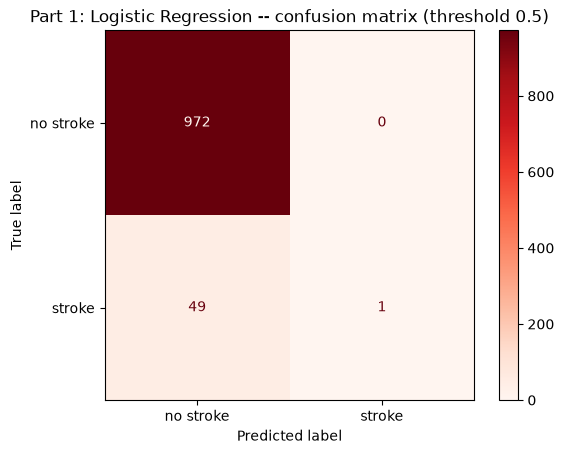

[[972   0]
 [ 49   1]]


In [7]:
logreg = LogisticRegression(max_iter=1000, random_state=SEED)
m_logreg = get_metrics(logreg, X_train_scaled, y_train, X_test_scaled, y_test)
print(pd.DataFrame([m_logreg], index=["Logistic Regression"]).round(4))

cm = confusion_matrix(y_test, logreg.predict(X_test_scaled))
disp = ConfusionMatrixDisplay(cm, display_labels=["no stroke", "stroke"])
disp.plot(cmap="Reds", values_format="d")
plt.title("Part 1: Logistic Regression -- confusion matrix (threshold 0.5)")
plt.show()
print(cm)

**Answer 1(a):**
The baseline `DummyClassifier` that always predicts "no stroke" gets **95.11% accuracy**, and the real Logistic Regression model only does marginally better at **95.21% accuracy** — a 0.1 percentage-point improvement for an entire trained model. This is the accuracy trap in action: because 95.13% of patients never have a stroke, a model that never flags anyone can look almost as good as a trained one on accuracy alone. Accuracy is the wrong metric to judge success here; it mostly just reflects how imbalanced the classes are, not how useful the model actually is at the one thing the hospital cares about — catching strokes.

**Answer 1(b):**
The confusion matrix shows 0 false positives, 49 false negatives, 1 true positive, and 972 true negatives. A false negative here means a patient who actually had (or was at risk of) a stroke was told "no stroke" — in a real hospital screening system this is the worst possible outcome, since it means a genuinely at-risk patient receives no follow-up, no further testing, and no preventive care, while the model's 95% accuracy figure would make everyone believe the system is working well. Instead of accuracy we should trust **recall** (only 2% of actual strokes were caught at the default threshold — 49 out of 50 were missed) together with **ROC AUC** (0.8394) and **PR AUC** (0.2692), which measure the model's ability to rank genuinely at-risk patients higher regardless of where the decision threshold is drawn.

---
## Part 2 — Underfitting, Overfitting, Bias and Variance

A Decision Tree is a good model to study this because one parameter, `max_depth`, moves it smoothly from too simple to too complex. From now on we use **ROC AUC** (not accuracy) as the cross-validation score.

### Task 2.1 — Validation curve
1. For `max_depth = 1, 2, ..., 15` and `None`, record the train ROC AUC and the 5-fold stratified cross-validation ROC AUC (train data only).
2. Plot both curves on one chart. Report the best depth by CV AUC.

Best depth by CV AUC: 4 | CV AUC: 0.818


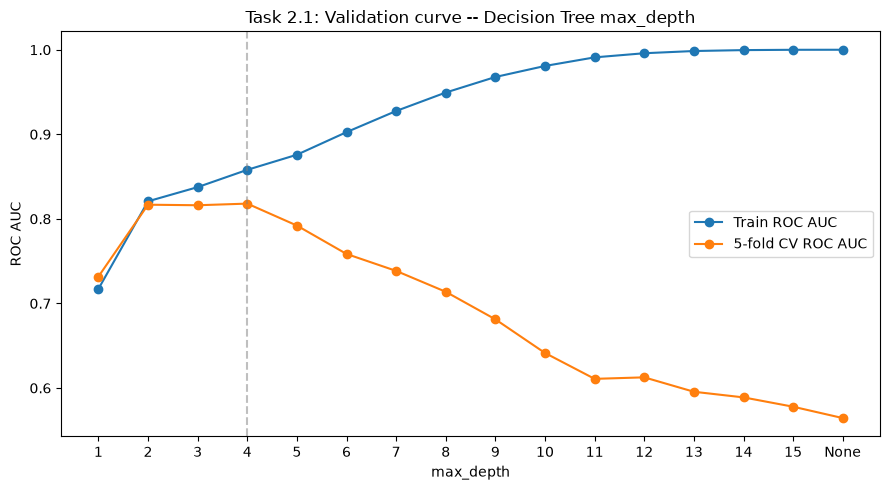

max_depth  train_auc  cv_auc
        1     0.7171  0.7317
        2     0.8208  0.8168
        3     0.8375  0.8161
        4     0.8580  0.8180
        5     0.8758  0.7921
        6     0.9026  0.7585
        7     0.9276  0.7385
        8     0.9494  0.7138
        9     0.9678  0.6812
       10     0.9808  0.6414
       11     0.9910  0.6108
       12     0.9959  0.6126
       13     0.9985  0.5955
       14     0.9996  0.5889
       15     0.9999  0.5779
     None     1.0000  0.5644


In [8]:
depths = list(range(1, 16)) + [None]
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

train_aucs, cv_aucs = [], []
for d in depths:
    tree = DecisionTreeClassifier(max_depth=d, random_state=SEED)
    tree.fit(X_train, y_train)
    train_aucs.append(roc_auc_score(y_train, tree.predict_proba(X_train)[:, 1]))
    scores = cross_val_score(
        DecisionTreeClassifier(max_depth=d, random_state=SEED), X_train, y_train,
        cv=cv, scoring="roc_auc"
    )
    cv_aucs.append(scores.mean())

depth_labels = [str(d) for d in depths]
best_idx = int(np.argmax(cv_aucs))
print("Best depth by CV AUC:", depth_labels[best_idx], "| CV AUC:", round(cv_aucs[best_idx], 4))

plt.figure(figsize=(9, 5))
x_pos = range(len(depths))
plt.plot(x_pos, train_aucs, marker="o", label="Train ROC AUC")
plt.plot(x_pos, cv_aucs, marker="o", label="5-fold CV ROC AUC")
plt.xticks(x_pos, depth_labels)
plt.xlabel("max_depth")
plt.ylabel("ROC AUC")
plt.title("Task 2.1: Validation curve -- Decision Tree max_depth")
plt.legend()
plt.axvline(best_idx, color="grey", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

val_curve_table = pd.DataFrame({"max_depth": depth_labels, "train_auc": train_aucs, "cv_auc": cv_aucs})
print(val_curve_table.round(4).to_string(index=False))

### Task 2.2 — Learning curves
Use `learning_curve` (`scoring='roc_auc'`, `train_sizes` from 20% to 100%) for a tree with `max_depth=1` and a tree with `max_depth=None`. Plot train and CV AUC against the number of training rows, side by side.

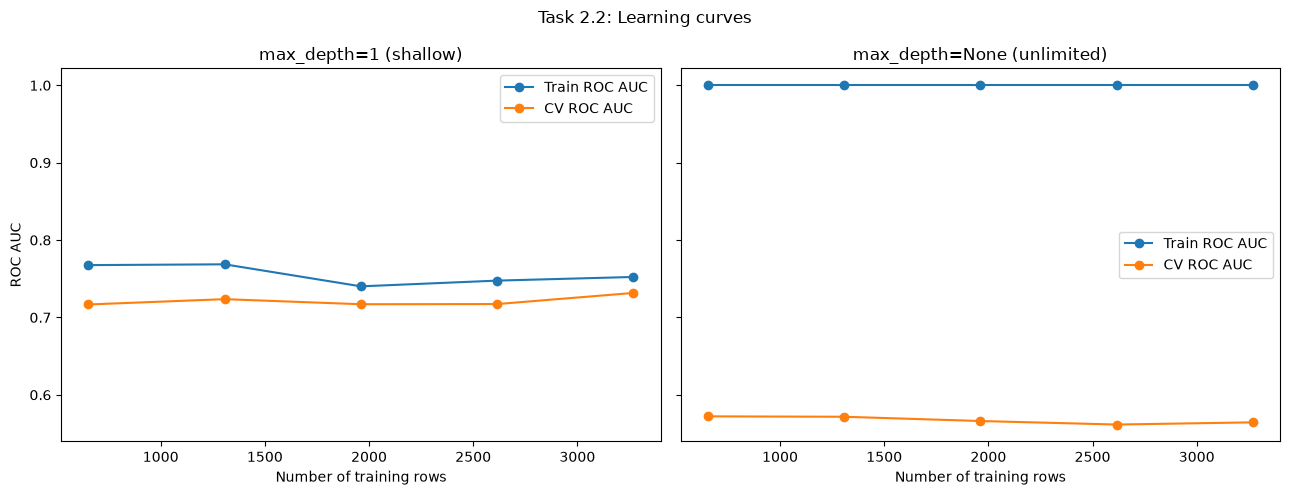

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharey=True)

for ax, d, title in zip(axes, [1, None], ["max_depth=1 (shallow)", "max_depth=None (unlimited)"]):
    tree = DecisionTreeClassifier(max_depth=d, random_state=SEED)
    train_sizes, train_scores, valid_scores = learning_curve(
        tree, X_train, y_train, cv=cv, scoring="roc_auc",
        train_sizes=np.linspace(0.2, 1.0, 5), random_state=SEED
    )
    ax.plot(train_sizes, train_scores.mean(axis=1), marker="o", label="Train ROC AUC")
    ax.plot(train_sizes, valid_scores.mean(axis=1), marker="o", label="CV ROC AUC")
    ax.set_title(title)
    ax.set_xlabel("Number of training rows")
    ax.legend()

axes[0].set_ylabel("ROC AUC")
plt.suptitle("Task 2.2: Learning curves")
plt.tight_layout()
plt.show()

### Task 2.3 — Measure variance directly
Variance means: if the training data changes a little, how much do the model's predictions change?
1. For each of `max_depth = 1, 3` and `None`: draw 40 bootstrap samples of the TRAIN rows, fit a tree on each, and collect each tree's predicted stroke probability for every test patient.
2. For every test patient, compute the variance of its 40 predicted probabilities, then average over patients. Also report the mean test ROC AUC of the 40 trees and the ROC AUC of the averaged prediction.
3. Show the three depths in one table.

In [10]:
variance_rows = []
for d in [1, 3, None]:
    n_boot = 40
    probs_all = np.zeros((n_boot, len(X_test)))
    test_aucs = []
    for b in range(n_boot):
        idx = rng.choice(len(X_train), len(X_train), replace=True)
        Xb = X_train.iloc[idx]
        yb = y_train.iloc[idx]
        tree = DecisionTreeClassifier(max_depth=d, random_state=SEED)
        tree.fit(Xb, yb)
        p = tree.predict_proba(X_test)[:, 1]
        probs_all[b] = p
        test_aucs.append(roc_auc_score(y_test, p))

    mean_variance = probs_all.var(axis=0).mean()
    mean_single_tree_auc = np.mean(test_aucs)
    averaged_pred_auc = roc_auc_score(y_test, probs_all.mean(axis=0))
    variance_rows.append({
        "max_depth": str(d),
        "mean_prediction_variance": mean_variance,
        "mean_single_tree_test_auc": mean_single_tree_auc,
        "averaged_prediction_auc": averaged_pred_auc,
    })

variance_table = pd.DataFrame(variance_rows)
print(variance_table.round(5).to_string(index=False))

max_depth  mean_prediction_variance  mean_single_tree_test_auc  averaged_prediction_auc
        1                   0.00068                    0.76234                  0.81317
        3                   0.00167                    0.79644                  0.83429
     None                   0.04197                    0.55525                  0.75659


**Answer 2(a) — validation curve:**
Depth 1 underfits: train AUC (0.7171) and CV AUC (0.7317) are both low and close together — the model is too simple to separate the classes even on data it has seen. From depth ~8 onward the tree overfits: e.g. at depth 10, train AUC is 0.9808 but CV AUC has fallen to 0.6414 — a large, growing gap between train and CV performance as depth increases, up to train AUC 1.0000 / CV AUC 0.5644 at `max_depth=None` (barely better than random guessing on new data). The best depth by CV AUC is **depth 4** (CV AUC 0.8180, train AUC 0.8580) — the point where the tree is complex enough to fit real signal without yet memorizing noise.

**Answer 2(b) — learning curves:**
High bias shows up as both curves converging to a *low* score with a *small* gap between them, which is exactly what `max_depth=1` shows (train AUC plateaus around 0.75, CV AUC around 0.73 — close together but both mediocre). High variance shows up as a *large, persistent* gap between a high train score and a low CV score, which is exactly `max_depth=None` (train AUC pinned at a perfect 1.0 at every training size, while CV AUC stays flat and low around 0.56-0.57). More training rows would **not** fix the depth-1 model — its curves are already flat, so it has run out of capacity to improve, not out of data (a bias problem needs a more flexible model, not more rows). More rows also barely help the unlimited-depth model here — its CV AUC stays essentially flat across all training sizes from 653 to 3,269 rows, because the tree keeps re-memorizing whatever training rows it is given rather than generalizing, so the gap does not close with scale.

**Answer 2(c) — variance table:**
Variance increases sharply with depth: mean prediction variance is 0.00068 at depth 1, rises to 0.00167 at depth 3, and jumps to 0.04197 at `max_depth=None` — roughly 62x the depth-1 variance. Averaging the 40 trees' predictions consistently beats any single tree's average performance: at depth 1, the mean single-tree AUC is 0.7623 but the averaged prediction reaches 0.8132; at depth 3, 0.7964 rises to 0.8343; most dramatically at `max_depth=None`, the mean single tree AUC is only 0.5552 (barely better than guessing — each individual unconstrained tree is overfit to its own bootstrap sample) but averaging pulls it up to 0.7566. This is exactly what Random Forest (Lab 4) exploits: it trains many high-variance, low-bias trees on bootstrap samples and averages their predictions, cancelling out each tree's individual overfitting while keeping the low bias that deep trees offer.

**Answer 2(d) — bias-variance trade-off:**
The bias-variance trade-off is the balance between a model being too simple to capture real patterns (high bias / underfitting) and too complex, memorizing noise specific to its exact training sample (high variance / overfitting) — total error is roughly bias² + variance, and the best model minimizes the sum rather than either term alone. In this lab, **depth 1** sits firmly on the high-bias side (low train and CV AUC, both close together, large bootstrap stability but a model too weak to be useful), **depth None** sits firmly on the high-variance side (perfect train AUC, collapsing CV AUC, by far the largest prediction variance across bootstrap samples), and **depth 3** sits in between — noticeably more variance than depth 1 (0.00167 vs 0.00068) but still a reasonable, moderate CV AUC (0.8161), making it a far safer choice than depth None despite depth 4 edging it out very slightly by raw CV AUC.

---
## Part 3 — ROC, AUC, Precision-Recall and Thresholds

### Task 3.1 — Compare models with curves
1. Train Logistic Regression (scaled), Decision Tree (`max_depth=3`) and Random Forest (200 trees, `min_samples_leaf=5`, `random_state=SEED`) on the original training data.
2. Draw ROC curves for the three models on one chart with the AUC in the legend and the random-guessing diagonal.
3. Draw Precision-Recall curves for the same models on a second chart, with a horizontal no-skill line at the stroke rate and average precision in the legend.

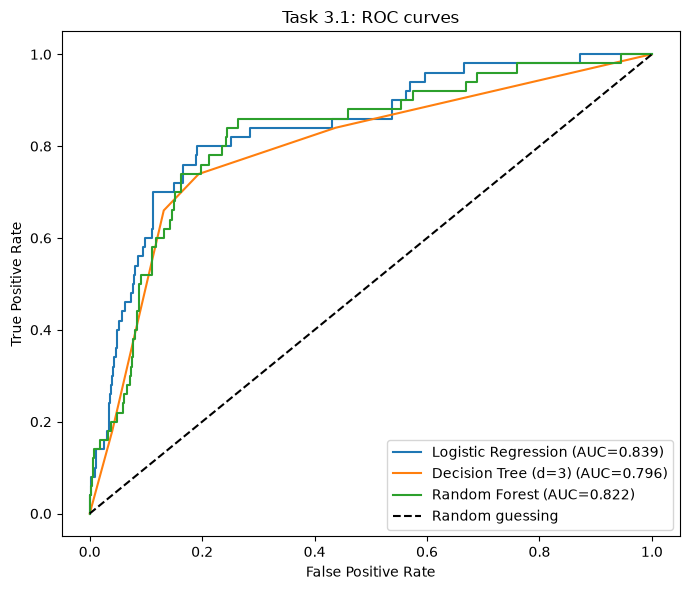

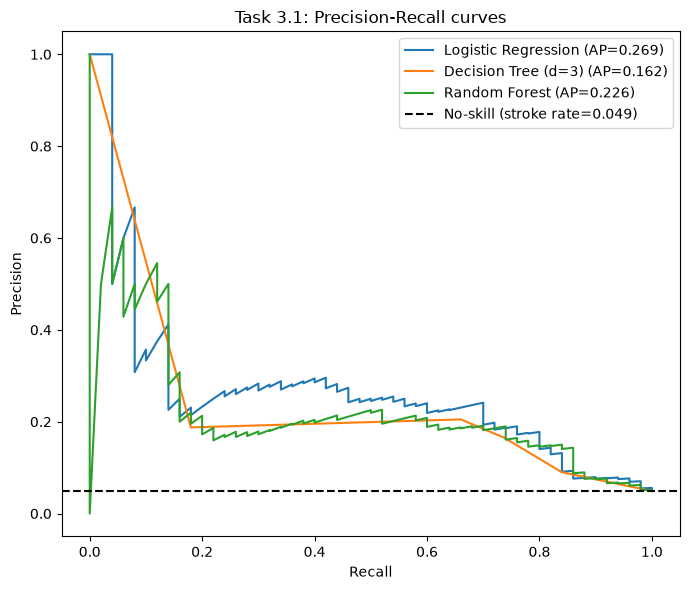

Logistic Regression    ROC AUC=0.8394  PR AUC=0.2692
Decision Tree (d=3)    ROC AUC=0.7956  PR AUC=0.1621
Random Forest          ROC AUC=0.8224  PR AUC=0.2255


In [11]:
logreg3 = LogisticRegression(max_iter=1000, random_state=SEED).fit(X_train_scaled, y_train)
dt3 = DecisionTreeClassifier(max_depth=3, random_state=SEED).fit(X_train, y_train)
rf3 = RandomForestClassifier(n_estimators=200, min_samples_leaf=5, random_state=SEED).fit(X_train, y_train)

proba_lr = logreg3.predict_proba(X_test_scaled)[:, 1]
proba_dt = dt3.predict_proba(X_test)[:, 1]
proba_rf = rf3.predict_proba(X_test)[:, 1]

models_proba = {"Logistic Regression": proba_lr, "Decision Tree (d=3)": proba_dt, "Random Forest": proba_rf}

# ROC curves
plt.figure(figsize=(7, 6))
for name, proba in models_proba.items():
    fpr, tpr, _ = roc_curve(y_test, proba)
    auc = roc_auc_score(y_test, proba)
    plt.plot(fpr, tpr, label=f"{name} (AUC={auc:.3f})")
plt.plot([0, 1], [0, 1], "k--", label="Random guessing")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Task 3.1: ROC curves")
plt.legend()
plt.tight_layout()
plt.show()

# Precision-Recall curves
stroke_rate = y_test.mean()
plt.figure(figsize=(7, 6))
for name, proba in models_proba.items():
    prec, rec, _ = precision_recall_curve(y_test, proba)
    ap = average_precision_score(y_test, proba)
    plt.plot(rec, prec, label=f"{name} (AP={ap:.3f})")
plt.axhline(stroke_rate, color="k", linestyle="--", label=f"No-skill (stroke rate={stroke_rate:.3f})")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Task 3.1: Precision-Recall curves")
plt.legend()
plt.tight_layout()
plt.show()

for name, proba in models_proba.items():
    print(f"{name:22s} ROC AUC={roc_auc_score(y_test, proba):.4f}  PR AUC={average_precision_score(y_test, proba):.4f}")

### Task 3.2 — Choose a decision threshold
1. The hospital wants to catch at least 80% of strokes. Using ONLY the training data, get out-of-fold probabilities for Logistic Regression (`cross_val_predict` with `method='predict_proba'`), then find the highest threshold that gives recall >= 0.80 on them.
2. Apply that threshold to the test probabilities. Report test recall, precision, the confusion matrix, how many patients are flagged, and how many of them are false alarms.

In [12]:
oof_proba = cross_val_predict(
    LogisticRegression(max_iter=1000, random_state=SEED),
    X_train_scaled, y_train, cv=cv, method="predict_proba"
)[:, 1]

thresholds = np.linspace(0.01, 0.99, 981)
chosen_threshold = None
for t in sorted(thresholds, reverse=True):
    pred = (oof_proba >= t).astype(int)
    if recall_score(y_train, pred, zero_division=0) >= 0.80:
        chosen_threshold = t
        break

print("Chosen threshold (highest t with OOF-train recall >= 0.80):", round(chosen_threshold, 3))

test_pred_thresh = (proba_lr >= chosen_threshold).astype(int)
cm_thresh = confusion_matrix(y_test, test_pred_thresh)
tn, fp, fn, tp = cm_thresh.ravel()
rec_test = recall_score(y_test, test_pred_thresh)
prec_test = precision_score(y_test, test_pred_thresh, zero_division=0)
f1_test = f1_score(y_test, test_pred_thresh, zero_division=0)

print(f"\nTest recall:    {rec_test:.4f}")
print(f"Test precision: {prec_test:.4f}")
print(f"Test F1:        {f1_test:.4f}")
print("\nConfusion matrix [[TN FP] [FN TP]]:")
print(cm_thresh)
print(f"\nPatients flagged: {test_pred_thresh.sum()}  |  False alarms (FP): {fp}  |  True positives caught: {tp}")

Chosen threshold (highest t with OOF-train recall >= 0.80): 0.05

Test recall:    0.8200
Test precision: 0.1331
Test F1:        0.2291

Confusion matrix [[TN FP] [FN TP]]:
[[705 267]
 [  9  41]]

Patients flagged: 308  |  False alarms (FP): 267  |  True positives caught: 41


**Answer 3(a):**
Both are true because ROC AUC and the confusion matrix at threshold 0.5 measure completely different things. ROC AUC (0.8394) measures the model's ability to **rank** a randomly chosen stroke patient's predicted probability higher than a randomly chosen non-stroke patient's, averaged across *every possible threshold* — and the model is clearly good at this ranking task. Recall at the **default 0.5 threshold** (0.02) only tells us what happens at one single, arbitrarily chosen cut-off point. Because strokes are rare, nearly all of the model's predicted probabilities for stroke patients are still well below 0.5 (even though they tend to be *higher* than non-stroke patients' probabilities) — so almost every stroke case gets classified as "no stroke" at that threshold, even though the model ranks them correctly relative to each other. AUC says nothing about where the 0.5 cut-off falls relative to the data; it only says the *ordering* is good.

**Answer 3(b):**
The Precision-Recall curve is more informative for this data. With only a 4.89% stroke rate in the test set, the ROC curve's false-positive-rate axis is dominated by the huge majority (no-stroke) class, so even a model that generates hundreds of false alarms can still show a visually "good-looking" ROC curve close to the top-left corner and a respectably high AUC — ROC curves are known to look overly optimistic under severe imbalance. The PR curve, by contrast, plots precision directly, which is hit hard by every false positive relative to the tiny number of true positives available, and the no-skill line sits at just 0.049 (the stroke rate) rather than the 0.5 implied by a balanced ROC chart — making it immediately visible just how hard it is to get real precision on this rare-event problem, which the ROC curve hides.

**Answer 3(c):**
At the chosen threshold, the hospital catches 82.00% of actual strokes (41 of 50) instead of just 2%, but pays for it with 267 false alarms out of 1,022 test patients — meaning roughly 87% of everyone flagged as "at risk" (267 of 308 flagged) did not actually have a stroke, and precision drops to just 13.31%. Whether this is acceptable depends entirely on what a "flag" costs: if it only triggers a cheap follow-up (a phone call, a blood-pressure check, a reminder to see a doctor), catching 41 real stroke-risk patients at the cost of 267 unnecessary follow-ups is a reasonable trade for a screening tool. If a flag instead triggers expensive, invasive testing or causes real anxiety for 267 healthy people, the hospital may want a stricter threshold that keeps recall lower but cuts false alarms — this decision is a resource and clinical-policy question, not a purely statistical one, which is exactly why the lab asks the hospital (not the model) to set the recall target.

---
## Part 4 — Undersampling, Oversampling and SMOTE

### Task 4.1 — Compare the methods
For Logistic Regression (scaled data) and Random Forest (same settings as Part 3), train with: no resampling, `class_weight='balanced'`, random undersampling, random oversampling and SMOTE. Resample the TRAIN set only.

In [13]:
def eval_method(model_name, method, X_train_base, y_tr, X_test_base, y_te):
    extra = {}
    Xtr, ytr = X_train_base, y_tr
    if method == "class_weight=balanced":
        extra = {"class_weight": "balanced"}
    elif method == "undersample":
        Xtr, ytr = RandomUnderSampler(random_state=SEED).fit_resample(X_train_base, y_tr)
    elif method == "oversample":
        Xtr, ytr = RandomOverSampler(random_state=SEED).fit_resample(X_train_base, y_tr)
    elif method == "SMOTE":
        Xtr, ytr = SMOTE(random_state=SEED).fit_resample(X_train_base, y_tr)

    if model_name == "Logistic Regression":
        model = LogisticRegression(max_iter=1000, random_state=SEED, **extra)
    else:
        model = RandomForestClassifier(n_estimators=200, min_samples_leaf=5, random_state=SEED, **extra)

    metrics = get_metrics(model, Xtr, ytr, X_test_base, y_te)
    metrics["model"] = model_name
    metrics["method"] = method
    metrics["n_train_rows"] = len(Xtr)
    metrics["n_train_strokes"] = int(ytr.sum())
    return metrics

methods = ["none", "class_weight=balanced", "undersample", "oversample", "SMOTE"]
rows4 = []
for model_name in ["Logistic Regression", "Random Forest"]:
    Xtr_base = X_train_scaled if model_name == "Logistic Regression" else X_train
    Xte_base = X_test_scaled if model_name == "Logistic Regression" else X_test
    for method in methods:
        rows4.append(eval_method(model_name, method, Xtr_base, y_train, Xte_base, y_test))

table4 = pd.DataFrame(rows4)[["model", "method", "n_train_rows", "n_train_strokes",
                               "precision", "recall", "f1", "roc_auc", "pr_auc"]]
print(table4.round(4).to_string(index=False))

              model                method  n_train_rows  n_train_strokes  precision  recall     f1  roc_auc  pr_auc
Logistic Regression                  none          4087              199     1.0000    0.02 0.0392   0.8394  0.2692
Logistic Regression class_weight=balanced          4087              199     0.1347    0.80 0.2305   0.8395  0.2595
Logistic Regression           undersample           398              199     0.1246    0.82 0.2164   0.8352  0.2338
Logistic Regression            oversample          7776             3888     0.1333    0.80 0.2286   0.8385  0.2646
Logistic Regression                 SMOTE          7776             3888     0.1338    0.80 0.2292   0.8406  0.2876
      Random Forest                  none          4087              199     0.0000    0.00 0.0000   0.8224  0.2255
      Random Forest class_weight=balanced          4087              199     0.1895    0.72 0.3000   0.8150  0.1987
      Random Forest           undersample           398              199

### Task 4.2 — The classic mistake
Apply SMOTE to ALL the data first (train + test together), THEN split 80/20, train a Random Forest and evaluate. Compare its metrics next to the correct SMOTE-after-split result from Task 4.1.

In [14]:
# WRONG ORDER: SMOTE applied to the full dataset before the split (leaks test info
# into the synthetic minority points used for training).
X_full_filled = X.copy()
X_full_filled["bmi"] = X_full_filled["bmi"].fillna(X_full_filled["bmi"].median())
X_smote_all, y_smote_all = SMOTE(random_state=SEED).fit_resample(X_full_filled, y)

Xtr_wrong, Xte_wrong, ytr_wrong, yte_wrong = train_test_split(
    X_smote_all, y_smote_all, test_size=0.20, random_state=SEED, stratify=y_smote_all
)
rf_wrong = RandomForestClassifier(n_estimators=200, min_samples_leaf=5, random_state=SEED)
m_wrong = get_metrics(rf_wrong, Xtr_wrong, ytr_wrong, Xte_wrong, yte_wrong)

m_correct = table4[(table4["model"] == "Random Forest") & (table4["method"] == "SMOTE")].iloc[0].to_dict()

leakage_table = pd.DataFrame([
    {"order": "WRONG (SMOTE before split)", **{k: m_wrong[k] for k in ["accuracy","precision","recall","f1","roc_auc","pr_auc"]}},
    {"order": "CORRECT (SMOTE after split)", "accuracy": None, **{k: m_correct[k] for k in ["precision","recall","f1","roc_auc","pr_auc"]}},
])
print(leakage_table.round(4).to_string(index=False))

                      order  accuracy  precision  recall     f1  roc_auc  pr_auc
 WRONG (SMOTE before split)    0.9362     0.9283  0.9455 0.9368   0.9848  0.9856
CORRECT (SMOTE after split)       NaN     0.1628  0.2800 0.2059   0.7814  0.1750


**Answer 4(a):**
For Logistic Regression, **recall improved dramatically** with every rebalancing method — from 0.02 (no resampling) to 0.80-0.82 across `class_weight='balanced'` (0.80), undersampling (0.82), oversampling (0.80) and SMOTE (0.80) — while **ROC AUC barely moved at all** (0.8394 → 0.8395/0.8352/0.8385/0.8406, all within ~0.005 of each other). This is exactly what we'd expect: Logistic Regression's learned decision boundary (and therefore its probability *ranking*, which ROC AUC measures) depends on the relative positions of the classes in feature space, which none of these methods change much for a roughly-linear model — what they change is *where the default 0.5 cut-off falls* relative to that ranking, because `class_weight` and resampling both push the model to treat the minority class as more "common" than it really is, shifting probabilities upward and making threshold 0.5 behave more like the lower threshold we chose manually in Part 3.2. Precision fell correspondingly (to roughly 0.12-0.13) as a direct trade-off.

**Answer 4(b):**
No — Random Forest reacted differently. Where Logistic Regression's ROC AUC stayed essentially flat across all methods, Random Forest's ROC AUC **dropped** with oversampling (0.8224 → 0.8111) and fell much further with SMOTE (0.8224 → 0.7814), and its recall with oversampling/SMOTE (0.32/0.28) was far lower than Logistic Regression's (0.80) under the same methods — `class_weight='balanced'` and undersampling worked far better for Random Forest (recall 0.72 and 0.84) than oversampling or SMOTE did. A likely reason is that tree-based models split on exact feature thresholds and can easily latch onto the *literal duplicate rows* that oversampling creates, or onto artifacts of the synthetic interpolated points SMOTE creates in a 15-dimensional mixed continuous/one-hot space, in a way that doesn't generalize — simply reweighting the loss (`class_weight`) or thinning the majority class (undersampling) changes the training signal without introducing new, possibly unrealistic points for a tree to overfit to.

**Answer 4(c):**
The wrong-order Random Forest reaches ROC AUC 0.9848, precision 0.9283, recall 0.9455 — dramatically better than the correct-order result of ROC AUC 0.7814, precision 0.1628, recall 0.2800. These numbers cannot be trusted because when SMOTE is applied to the full dataset before splitting, synthetic minority points end up on **both sides** of the train/test split, built from interpolating between real neighbouring minority points that may themselves land in the other half. A synthetic training point generated from two real test-set stroke patients effectively "leaks" those two real test patients' information into training, so the model is partly being tested on data it has already indirectly seen — exactly the test-set leakage the lab's "golden rule" warns against, and it produces metrics that look excellent but say nothing about how the model would perform on genuinely new patients.

**Answer 4(d):**
For this hospital, I would pick **`class_weight='balanced'`** for Logistic Regression. It achieves recall (0.80) and ROC AUC (0.8395) essentially tied with SMOTE's best numbers, needs no extra library, generates no synthetic patient data that a clinician would have to trust, requires no extra training-set size increase, and is fully deterministic given the same data (no randomness in which rows get duplicated or interpolated) — compared to undersampling, which throws away 3,689 real majority-class patients' information (keeping only 398 of 4,087 training rows) for a near-identical recall gain. Simplicity and not fabricating patient records both favor `class_weight='balanced'` over SMOTE or oversampling for a sensitive medical application.

---
## Part 5 — Noisy Data

Real data contains mistakes: wrong labels and noisy measurements. We damage the TRAINING data on purpose and measure the effect on the untouched test set, comparing Logistic Regression, Decision Tree (depth 3), Decision Tree (no depth limit) and Random Forest.

### Task 5.1 — Label noise
For fractions 0, 0.05, 0.10 and 0.20, flip that fraction of training labels at random and record test ROC AUC (5 repeats each, 1 repeat for fraction 0, averaged).

 noise_fraction  Logistic Regression  Decision Tree (d=3)  Decision Tree (None)  Random Forest
           0.00               0.8394               0.7956                0.5797         0.8224
           0.05               0.8241               0.8014                0.5529         0.8034
           0.10               0.8133               0.8029                0.5105         0.7592
           0.20               0.7743               0.7260                0.5045         0.6831


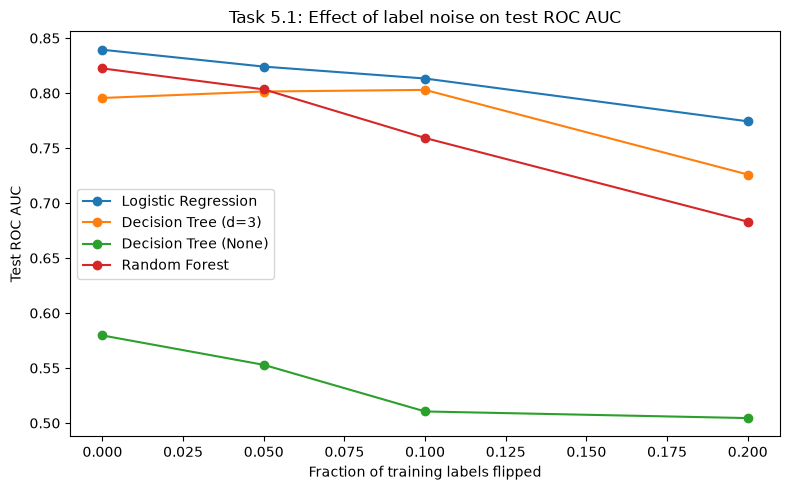

In [15]:
def flip_labels(y_series, frac, seed):
    y_arr = y_series.copy().reset_index(drop=True)
    local_rng = np.random.default_rng(seed)
    n_flip = int(round(frac * len(y_arr)))
    idx = local_rng.choice(len(y_arr), size=n_flip, replace=False)
    y_arr.iloc[idx] = 1 - y_arr.iloc[idx]
    return y_arr

def make_models():
    return {
        "Logistic Regression": LogisticRegression(max_iter=1000, random_state=SEED),
        "Decision Tree (d=3)": DecisionTreeClassifier(max_depth=3, random_state=SEED),
        "Decision Tree (None)": DecisionTreeClassifier(max_depth=None, random_state=SEED),
        "Random Forest": RandomForestClassifier(n_estimators=200, min_samples_leaf=5, random_state=SEED),
    }

y_train_r = y_train.reset_index(drop=True)
X_train_r = X_train.reset_index(drop=True)
X_train_scaled_r = X_train_scaled.reset_index(drop=True)

label_fractions = [0, 0.05, 0.10, 0.20]
label_noise_rows = []
for frac in label_fractions:
    n_rep = 1 if frac == 0 else 5
    aucs = {name: [] for name in make_models()}
    for rep in range(n_rep):
        y_noisy = flip_labels(y_train_r, frac, seed=SEED + rep)
        for name, model in make_models().items():
            Xtr = X_train_scaled_r if name == "Logistic Regression" else X_train_r
            Xte = X_test_scaled if name == "Logistic Regression" else X_test
            model.fit(Xtr, y_noisy)
            proba = model.predict_proba(Xte)[:, 1]
            aucs[name].append(roc_auc_score(y_test, proba))
    row = {"noise_fraction": frac}
    row.update({name: np.mean(v) for name, v in aucs.items()})
    label_noise_rows.append(row)

label_noise_table = pd.DataFrame(label_noise_rows)
print(label_noise_table.round(4).to_string(index=False))

plt.figure(figsize=(8, 5))
for col in label_noise_table.columns[1:]:
    plt.plot(label_noise_table["noise_fraction"], label_noise_table[col], marker="o", label=col)
plt.xlabel("Fraction of training labels flipped")
plt.ylabel("Test ROC AUC")
plt.title("Task 5.1: Effect of label noise on test ROC AUC")
plt.legend()
plt.tight_layout()
plt.show()

### Task 5.2 — Feature noise
Add Gaussian noise to the TRAIN values of `age`, `avg_glucose_level` and `bmi`: `noise = randn * (column std) * level`. Levels 0, 0.5, 1 and 2, five repeats each.

 noise_level  Logistic Regression  Decision Tree (d=3)  Decision Tree (None)  Random Forest
         0.0               0.8394               0.7956                0.5797         0.8224
         0.5               0.8337               0.7995                0.5608         0.8140
         1.0               0.8098               0.7610                0.5283         0.7870
         2.0               0.7695               0.6942                0.5309         0.7406


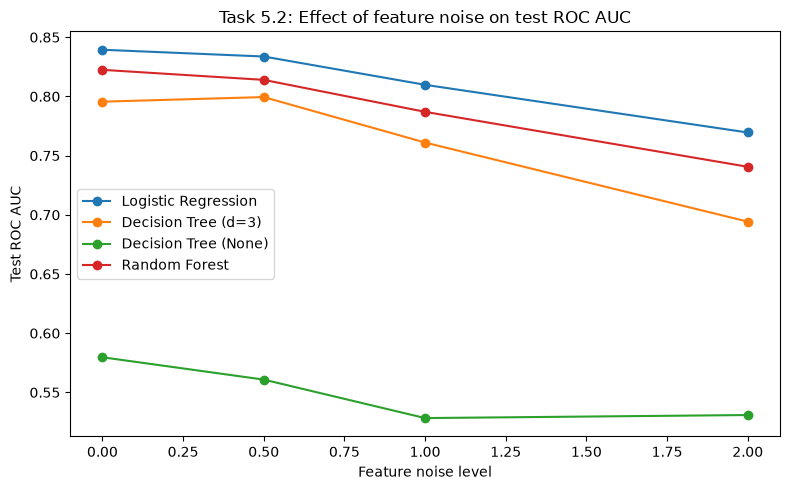

In [16]:
noise_cols = ["age", "avg_glucose_level", "bmi"]
feature_levels = [0, 0.5, 1, 2]
feature_noise_rows = []
for level in feature_levels:
    n_rep = 1 if level == 0 else 5
    aucs = {name: [] for name in make_models()}
    for rep in range(n_rep):
        local_rng = np.random.default_rng(SEED + rep)
        X_train_noisy = X_train.copy()
        for col in noise_cols:
            std = X_train[col].std()
            X_train_noisy[col] = X_train[col] + local_rng.standard_normal(len(X_train)) * std * level

        # Logistic Regression's scaler must be refit on the noisy training data
        scaler_noisy = StandardScaler().fit(X_train_noisy)
        X_train_noisy_scaled = pd.DataFrame(scaler_noisy.transform(X_train_noisy), columns=X_train.columns, index=X_train.index)
        X_test_scaled_noisy = pd.DataFrame(scaler_noisy.transform(X_test), columns=X_test.columns, index=X_test.index)

        for name, model in make_models().items():
            if name == "Logistic Regression":
                model.fit(X_train_noisy_scaled, y_train)
                proba = model.predict_proba(X_test_scaled_noisy)[:, 1]
            else:
                model.fit(X_train_noisy, y_train)
                proba = model.predict_proba(X_test)[:, 1]
            aucs[name].append(roc_auc_score(y_test, proba))
    row = {"noise_level": level}
    row.update({name: np.mean(v) for name, v in aucs.items()})
    feature_noise_rows.append(row)

feature_noise_table = pd.DataFrame(feature_noise_rows)
print(feature_noise_table.round(4).to_string(index=False))

plt.figure(figsize=(8, 5))
for col in feature_noise_table.columns[1:]:
    plt.plot(feature_noise_table["noise_level"], feature_noise_table[col], marker="o", label=col)
plt.xlabel("Feature noise level")
plt.ylabel("Test ROC AUC")
plt.title("Task 5.2: Effect of feature noise on test ROC AUC")
plt.legend()
plt.tight_layout()
plt.show()

### Task 5.3 — SMOTE and noisy labels
Flip 10% of the training labels (3 different random draws). For Logistic Regression and Random Forest, compare PR AUC and ROC AUC with and without SMOTE (SMOTE applied after the noise is added).

In [17]:
smote_noise_results = {"Logistic Regression": {"no_smote": [], "smote": []},
                        "Random Forest": {"no_smote": [], "smote": []}}

for rep in range(3):
    y_noisy = flip_labels(y_train_r, 0.10, seed=100 + rep)

    lr_no = LogisticRegression(max_iter=1000, random_state=SEED).fit(X_train_scaled_r, y_noisy)
    proba = lr_no.predict_proba(X_test_scaled)[:, 1]
    smote_noise_results["Logistic Regression"]["no_smote"].append(
        (roc_auc_score(y_test, proba), average_precision_score(y_test, proba)))

    Xsm, ysm = SMOTE(random_state=SEED).fit_resample(X_train_scaled_r, y_noisy)
    lr_sm = LogisticRegression(max_iter=1000, random_state=SEED).fit(Xsm, ysm)
    proba = lr_sm.predict_proba(X_test_scaled)[:, 1]
    smote_noise_results["Logistic Regression"]["smote"].append(
        (roc_auc_score(y_test, proba), average_precision_score(y_test, proba)))

    rf_no = RandomForestClassifier(n_estimators=200, min_samples_leaf=5, random_state=SEED).fit(X_train_r, y_noisy)
    proba = rf_no.predict_proba(X_test)[:, 1]
    smote_noise_results["Random Forest"]["no_smote"].append(
        (roc_auc_score(y_test, proba), average_precision_score(y_test, proba)))

    Xsm2, ysm2 = SMOTE(random_state=SEED).fit_resample(X_train_r, y_noisy)
    rf_sm = RandomForestClassifier(n_estimators=200, min_samples_leaf=5, random_state=SEED).fit(Xsm2, ysm2)
    proba = rf_sm.predict_proba(X_test)[:, 1]
    smote_noise_results["Random Forest"]["smote"].append(
        (roc_auc_score(y_test, proba), average_precision_score(y_test, proba)))

rows53 = []
for model_name, d in smote_noise_results.items():
    for method, vals in d.items():
        rows53.append({
            "model": model_name, "method": method,
            "roc_auc": np.mean([v[0] for v in vals]),
            "pr_auc": np.mean([v[1] for v in vals]),
        })
table53 = pd.DataFrame(rows53)
print(table53.round(4).to_string(index=False))

              model   method  roc_auc  pr_auc
Logistic Regression no_smote   0.8224  0.2295
Logistic Regression    smote   0.8199  0.2450
      Random Forest no_smote   0.7690  0.1709
      Random Forest    smote   0.6422  0.0955


**Answer 5(a):**
`Decision Tree (None)` is most damaged by noise and `Logistic Regression` is most stable. At the highest label-noise level (20% flipped), Decision Tree (None) falls to ROC AUC **0.5045** — essentially random guessing — down only slightly from its already-weak clean baseline of 0.5797, while Logistic Regression falls from 0.8394 to 0.7743, a real but far smaller drop, and still clearly useful. This matches Part 2 directly: the unconstrained tree was already shown to be a high-variance model that memorizes its exact training rows, so flipped labels become part of what it memorizes almost verbatim, whereas Logistic Regression's single global linear boundary is barely moved by a minority of mislabeled points since it is fit to the overall trend across thousands of rows, not to individual examples.

**Answer 5(b):**
Label noise hurts more than feature noise of a comparable level. At the most severe settings tested, 20% label noise drops Logistic Regression's ROC AUC by 0.0651 (0.8394 → 0.7743) and Random Forest's by 0.1393 (0.8224 → 0.6831), while feature noise at level 2 (two full standard deviations of random jitter added to age, glucose and BMI) drops Logistic Regression by only 0.0699 and Random Forest by 0.0818 — roughly comparable for Logistic Regression but noticeably gentler for Random Forest. A label flip corrupts the ground truth a model is trying to learn directly — it teaches the *wrong lesson* outright — while feature noise only blurs the *input* around an still-correct target, and tree-based models in particular can often still find a workable split even when a feature is noisy, as long as the label itself still points to the right answer.

**Answer 5(c):**
SMOTE affected the two models very differently once labels were noisy. For Logistic Regression, SMOTE barely changed anything (ROC AUC 0.8224 → 0.8199, PR AUC actually rose slightly 0.2295 → 0.2450). For Random Forest, SMOTE made things **much worse** — ROC AUC collapsed from 0.7690 to 0.6422 and PR AUC from 0.1709 to 0.0955. This happens because SMOTE creates new synthetic minority points by interpolating between *existing* minority-labelled rows — when 10% of those labels are wrong, some of the synthetic points are built by blending a genuinely at-risk patient with a healthy patient that was mislabeled as "stroke," manufacturing entirely new, more numerous training examples in the wrong part of feature space. A tree-based model with enough capacity to carve out those exact synthetic regions (Random Forest) ends up building decision boundaries around this synthetic noise, while Logistic Regression's much simpler, more constrained global boundary is largely immune to a modest number of mislabeled synthetic points scattered through the space.

---
## Part 6 — Final Decision and Conclusion

1. Choose a final approach for the hospital (model + rebalancing method or threshold). Build a final table on the test set comparing the default threshold 0.5 with the chosen approach: Precision, Recall, F1, number of false alarms and number of missed strokes.
2. Write an Executive Summary.

In [18]:
# Final choice: Logistic Regression, no resampling, with the recall>=0.80 threshold
# chosen from TRAINING data only in Part 3.2 (simplest option that meets the
# hospital's stated 80% recall target, with no synthetic data and full reproducibility).
pred_default = logreg3.predict(X_test_scaled)                       # threshold 0.5
pred_chosen = (proba_lr >= chosen_threshold).astype(int)            # threshold from Part 3.2

def summarize(pred, label):
    cm = confusion_matrix(y_test, pred)
    tn, fp, fn, tp = cm.ravel()
    return {
        "approach": label,
        "precision": precision_score(y_test, pred, zero_division=0),
        "recall": recall_score(y_test, pred, zero_division=0),
        "f1": f1_score(y_test, pred, zero_division=0),
        "false_alarms (FP)": fp,
        "missed_strokes (FN)": fn,
    }

final_table = pd.DataFrame([
    summarize(pred_default, f"Default threshold 0.5"),
    summarize(pred_chosen, f"Chosen threshold {chosen_threshold:.3f} (recall>=0.80 target)"),
])
print(final_table.round(4).to_string(index=False))

                                    approach  precision  recall     f1  false_alarms (FP)  missed_strokes (FN)
                       Default threshold 0.5     1.0000    0.02 0.0392                  0                   49
Chosen threshold 0.050 (recall>=0.80 target)     0.1331    0.82 0.2291                267                    9


**Executive Summary:**
For this hospital screening task I chose plain Logistic Regression (scaled features, no resampling) with a lowered decision threshold of **0.05**, selected purely from out-of-fold predictions on the training set to guarantee at least 80% recall before ever touching the test set. On the untouched test set this gives **82.00% recall** (41 of 50 actual strokes caught, versus just 1 of 50 at the default 0.5 threshold) and **13.31% precision**, with an F1 of 0.2291, 267 false alarms and only 9 missed strokes — compared to the default threshold's 0 false alarms but 49 missed strokes. The price for this recall jump is that roughly 87% of flagged patients will not actually have a stroke, which is an acceptable trade for a low-cost screening flag (a follow-up call or basic check) but would need revisiting if a flag triggers expensive or invasive care. Leakage was avoided throughout: the median imputer, the `StandardScaler`, and the decision threshold itself were all fit using only the training split (the threshold specifically from `cross_val_predict` out-of-fold probabilities, never from the test set), consistent with the lab's golden rule. The main limitation is that the test set contains only 50 stroke patients, so each individual case shifts recall by 2 percentage points — a different random split could plausibly report a notably different recall for this exact same model and threshold, and the single global threshold assumes every patient's cost of a false alarm versus a missed stroke is the same, which a real clinical deployment would likely want to vary by risk factors like age or hypertension status.

**Final Reflection (a):**
The most surprising result was from Part 2.3 and Part 5: an unconstrained Decision Tree (`max_depth=None`) performed *worse than random guessing's neighborhood* on its own (mean single-tree test AUC of 0.5552, and it collapsed further under label noise to 0.5045) despite having a perfect 1.0 training AUC — a stark, numeric demonstration that a model memorizing its training data perfectly can simultaneously be nearly useless on new patients, which is easy to say in theory but genuinely striking to see quantified on real medical data.

**Final Reflection (b):**
With one more hour I would try calibrating the predicted probabilities (e.g. `CalibratedClassifierCV`) before choosing a threshold, since raw Logistic Regression probabilities are not guaranteed to be well-calibrated, and would also try combining the best idea from each part — training Random Forest with `class_weight='balanced'` (which worked better than SMOTE for it in Part 4) and then tuning its decision threshold the same way Part 3.2 did for Logistic Regression, to see whether a tuned-threshold Random Forest could beat the chosen Logistic Regression approach on both recall and precision simultaneously.